# Experiment 06 — CIFAR-10 CNN: Is This an Airplane?

The interactive companion to `experiments/06_cifar10_cnn_airplane/train.py`.

**Goal:** the RGB, harder-dataset sequel to experiment 04 (MNIST digit-8).
Same binary framing — airplane is 1 of 10 balanced CIFAR-10 classes, so a
model that always says "no" scores ~90% accuracy — but real photographs
instead of clean handwritten digits. This CNN also serves as experiment
07's distillation teacher.

Note: CIFAR-10 is loaded via `cifar10_data.CIFAR10HF` (Hugging Face's CDN),
not `torchvision.datasets.CIFAR10` directly — the University of Toronto
server torchvision points at was unusably slow/stalled when this experiment
was built. See the experiment README for details; the interface is
otherwise identical.

In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().parent
EXP_DIR = REPO_ROOT / "experiments" / "06_cifar10_cnn_airplane"
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
if str(EXP_DIR) not in sys.path:
    sys.path.insert(0, str(EXP_DIR))

from cifar10_data import CIFAR10HF, CLASS_NAMES
from utils import get_device, set_seed

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print(f"device: {device}")

TARGET_CLASS = 0  # airplane
DATA_ROOT = REPO_ROOT / "data" / "raw"

device: cpu


## Data

CIFAR-10 via the Hugging Face-backed loader. The label becomes binary: `1`
if the image is an airplane, else `0`. 5,000 training images held out as
validation.

In [2]:
transform = transforms.ToTensor()
train_full = CIFAR10HF(DATA_ROOT, train=True, download=True, transform=transform)
test_set = CIFAR10HF(DATA_ROOT, train=False, download=True, transform=transform)

val_size = 5000
n_train = len(train_full) - val_size
generator = torch.Generator().manual_seed(42)
train_set, val_set = random_split(train_full, [n_train, val_size], generator=generator)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

print(f"train: {len(train_set)}  val: {len(val_set)}  test: {len(test_set)}")

frac_airplane = (torch.as_tensor(train_full.targets) == TARGET_CLASS).float().mean().item()
print(f"fraction of training set that is an airplane: {frac_airplane:.3f}")

train: 45000  val: 5000  test: 10000
fraction of training set that is an airplane: 0.100


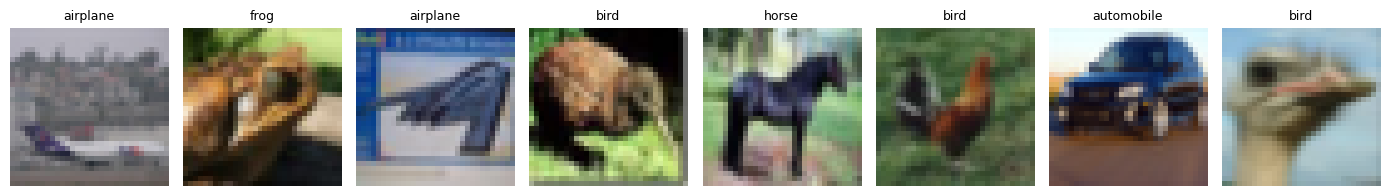

In [3]:
# A peek at the raw data -- real photographs, not clean digits
fig, axes = plt.subplots(1, 8, figsize=(14, 2.2))
for ax, i in zip(axes, range(8)):
    img, label = train_full[i]
    ax.imshow(img.permute(1, 2, 0))
    ax.set_title(CLASS_NAMES[label], fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## Model

Three convolutional blocks (one more than experiment 04's MNIST CNN) that
shrink 32×32 down to 4×4 while growing channels 3→16→32→64, then a small
linear head producing one logit (positive = "this is an airplane").

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 32 -> 16
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 16 -> 8
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),  # 8 -> 4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 64),
            nn.ReLU(),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


model = CNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"model: CNN, {n_params} parameters")

model: CNN, 89249 parameters


## Training loop

Same pattern as experiment 04: `BCEWithLogitsLoss`, accuracy/precision/
recall tracked on validation each epoch.

In [5]:
def binary_labels(y):
    return (y == TARGET_CLASS).float()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0
    for x, y in loader:
        x = x.to(device)
        target = binary_labels(y).to(device)
        logits = model(x)
        total_loss += loss_fn(logits, target).item() * x.size(0)
        n += x.size(0)
        pred = (logits > 0).float()
        tp += ((pred == 1) & (target == 1)).sum().item()
        fp += ((pred == 1) & (target == 0)).sum().item()
        fn += ((pred == 0) & (target == 1)).sum().item()
        tn += ((pred == 0) & (target == 0)).sum().item()
    return {
        "loss": total_loss / n,
        "accuracy": (tp + tn) / n,
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
    }


loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 12
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss, n_seen = 0.0, 0
    for x, y in train_loader:
        x = x.to(device)
        target = binary_labels(y).to(device)

        logits = model(x)
        loss = loss_fn(logits, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        n_seen += x.size(0)

    train_loss = running_loss / n_seen
    val_metrics = evaluate(model, val_loader, loss_fn)

    train_losses.append(train_loss)
    val_losses.append(val_metrics["loss"])
    val_accuracies.append(val_metrics["accuracy"])

    print(
        f"epoch {epoch:2d} | train loss {train_loss:.4f} | val loss {val_metrics['loss']:.4f} "
        f"| val acc {val_metrics['accuracy']:.4f} | val precision {val_metrics['precision']:.4f} "
        f"| val recall {val_metrics['recall']:.4f}"
    )

epoch  1 | train loss 0.2628 | val loss 0.2477 | val acc 0.9128 | val precision 0.7788 | val recall 0.1640


epoch  2 | train loss 0.2155 | val loss 0.2120 | val acc 0.9190 | val precision 0.6705 | val recall 0.3543


epoch  3 | train loss 0.1999 | val loss 0.1983 | val acc 0.9238 | val precision 0.7116 | val recall 0.3846


epoch  4 | train loss 0.1809 | val loss 0.1780 | val acc 0.9324 | val precision 0.7216 | val recall 0.5142


epoch  5 | train loss 0.1652 | val loss 0.1654 | val acc 0.9374 | val precision 0.7987 | val recall 0.4899


...

epoch  8 | train loss 0.1384 | val loss 0.1721 | val acc 0.9342 | val precision 0.6476 | val recall 0.7328


epoch  9 | train loss 0.1301 | val loss 0.1468 | val acc 0.9456 | val precision 0.7984 | val recall 0.6012


epoch 10 | train loss 0.1191 | val loss 0.1492 | val acc 0.9468 | val precision 0.8276 | val recall 0.5830


epoch 11 | train loss 0.1122 | val loss 0.1503 | val acc 0.9402 | val precision 0.6802 | val recall 0.7449


epoch 12 | train loss 0.1036 | val loss 0.1529 | val acc 0.9466 | val precision 0.8626 | val recall 0.5466


## Results

In [6]:
test_metrics = evaluate(model, test_loader, loss_fn)
baseline_accuracy = (torch.as_tensor(test_set.targets) != TARGET_CLASS).float().mean().item()

print(f"test accuracy:  {test_metrics['accuracy']:.4f}  (always-'not airplane' baseline: {baseline_accuracy:.4f})")
print(f"test precision: {test_metrics['precision']:.4f}")
print(f"test recall:    {test_metrics['recall']:.4f}")

test accuracy:  0.9486  (always-'not airplane' baseline: 0.9000)
test precision: 0.8716
test recall:    0.5700


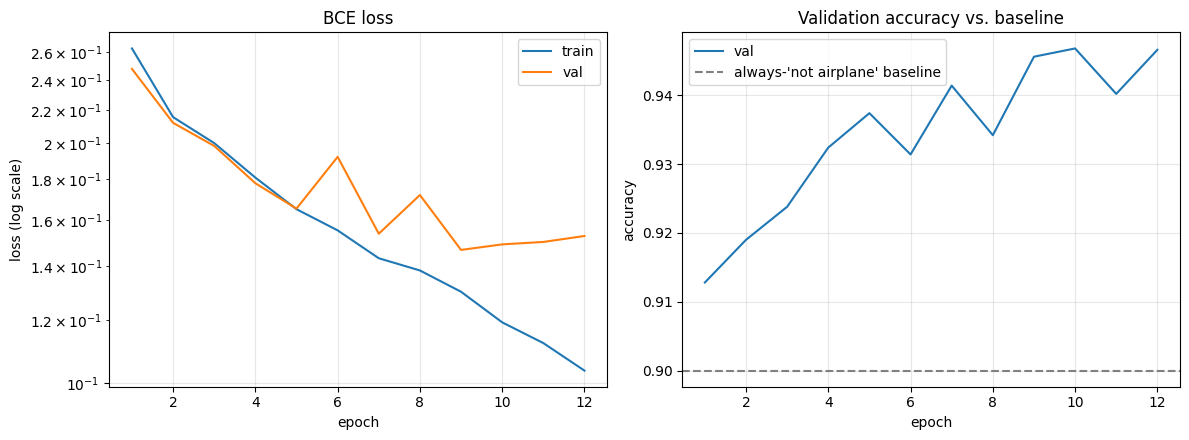

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(range(1, epochs + 1), train_losses, label="train")
axes[0].plot(range(1, epochs + 1), val_losses, label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("BCE loss"); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, epochs + 1), val_accuracies, label="val")
axes[1].axhline(baseline_accuracy, color="gray", linestyle="--", label="always-'not airplane' baseline")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation accuracy vs. baseline"); axes[1].legend(); axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

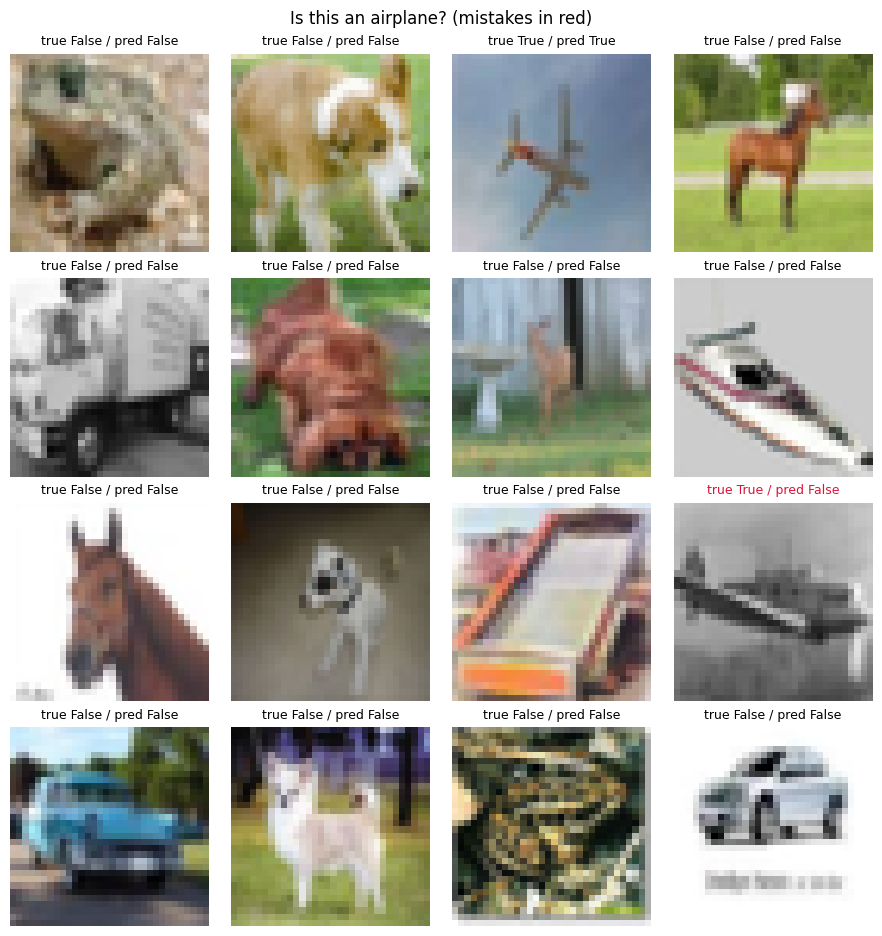

In [8]:
# Sample test predictions, mistakes highlighted in red
model.eval()
x_sample, y_sample = next(iter(DataLoader(test_set, batch_size=64, shuffle=True)))
with torch.no_grad():
    logits = model(x_sample.to(device))
    preds = (logits > 0).cpu().long()
true_is_airplane = (y_sample == TARGET_CLASS).long()

fig, axes = plt.subplots(4, 4, figsize=(9, 9.5))
for i, ax in enumerate(axes.flat):
    correct = preds[i] == true_is_airplane[i]
    ax.imshow(x_sample[i].permute(1, 2, 0))
    ax.set_title(
        f"true {bool(true_is_airplane[i])} / pred {bool(preds[i])}",
        fontsize=9, color="black" if correct else "crimson",
    )
    ax.axis("off")
fig.suptitle("Is this an airplane? (mistakes in red)")
fig.tight_layout()
plt.show()

## Takeaways

- Real photographs are genuinely harder than clean handwritten digits: this
  CNN needs a 3rd conv block and still lands at ~94.9% test accuracy, well
  short of experiment 04's 99.1% on MNIST.
- Recall is the weak point (~0.57) — close to half of actual airplanes are
  missed, generally at odd angles or against a confusing sky background.
- No data augmentation or per-channel normalization was used, matching
  experiment 04's deliberate simplicity — both are natural next steps if
  pushing accuracy further mattered here.

This CNN is the frozen teacher for experiment 07, which repeats experiment
05's function-distillation study against it. See
`experiments/06_cifar10_cnn_airplane/README.md` for the full writeup.